# Verificando se está chovendo ou não por meio de Regressão logística.
Dataset utilizado: https://www.kaggle.com/datasets/gaurav896/weather-in-australia


 Visão geral :

**Importando bibliotecas.**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from io import StringIO

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler

Carregando dados

In [ ]:

print('= Carregando Dataset =')
url = 'https://raw.githubusercontent.com/amankharwal/Website-data/master/weatherAUS.csv'

try:
    dadosnfor = pd.read_csv(url)
    print("Dataset carregado com sucesso!")
except:
    # Outra alternativa
    url = 'https://raw.githubusercontent.com/MicrosoftDocs/ml-basics/master/data/weather.csv'
    dadosnfor = pd.read_csv(url)
    print(' Dataset carregado da fonte alternativa! ')

dados = 'dados_meteorologicos_completo.xlsx'
dadosnfor.to_excel(dados, index = False)



= Carregando Dataset =
Dataset carregado com sucesso!


In [ ]:
dadosnfor['Date'] = pd.to_datetime(dadosnfor['Date'])
dadosnfor['Month'] = dadosnfor['Date'].dt.month
dadosnfor['Year'] = dadosnfor['Date'].dt.year
dadosnfor = dadosnfor.rename(columns={'Humidity3pm': 'Umidade3pm'})

tabelaReduzida = dadosnfor[['Date', 'Month', 'Year','MinTemp','MaxTemp','RainTomorrow', 'Umidade3pm']].copy()
tabelaReduzida.head()
tabelaReduzida.isnull().sum()

,0
Date,0
Month,0
Year,0
MinTemp,637
MaxTemp,322
RainTomorrow,0
Umidade3pm,3610


Limpando os dados

In [ ]:
tabelaformatada = tabelaReduzida.dropna(subset = ['Date','MinTemp','Month', 'Year','MaxTemp', 'Umidade3pm', 'RainTomorrow']).copy()

tabelaformatada['DataString'] = (
    tabelaformatada['Year'].astype(str) + '-'
    + tabelaformatada['Month'].astype(str) + '-'
    + tabelaformatada['Date'].dt.day.astype(str)
)

tabelaformatada['DataCompleta'] = pd.to_datetime(tabelaformatada['DataString'])
tabelaformatada['DiaDoAno'] = tabelaformatada['DataCompleta'].dt.dayofyear

# Corrigindo o mapeamento: Usar 'Yes' e 'No' em vez de 'Y' e 'N'
tabelaformatada['RainTomorrow'] = tabelaformatada['RainTomorrow'].map({'Yes': 1, 'No': 0})

tabelaformatada.head()

,Date,Month,Year,MinTemp,MaxTemp,RainTomorrow,Umidade3pm,DataString,DataCompleta,DiaDoAno
0,2008-12-01,12,2008,13.4,22.9,0,22.0,2008-12-1,2008-12-01,336
1,2008-12-02,12,2008,7.4,25.1,0,25.0,2008-12-2,2008-12-02,337
2,2008-12-03,12,2008,12.9,25.7,0,30.0,2008-12-3,2008-12-03,338
3,2008-12-04,12,2008,9.2,28.0,0,16.0,2008-12-4,2008-12-04,339
4,2008-12-05,12,2008,17.5,32.3,0,33.0,2008-12-5,2008-12-05,340


### Usando temperatura mínima e máxima


Primeira tentativa: Modelo acerta quando não vai chover.

= Resultados: =
Acurácia: 79.17%
               precision    recall  f1-score   support

Não Chove (0)       0.80      0.98      0.88     21465
    Chove (1)       0.67      0.13      0.22      6160

     accuracy                           0.79     27625
    macro avg       0.73      0.56      0.55     27625
 weighted avg       0.77      0.79      0.73     27625



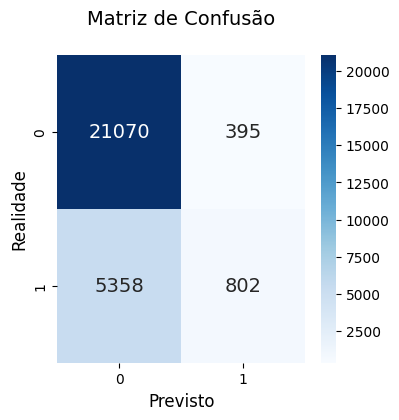

In [ ]:
x = tabelaformatada[['MinTemp','MaxTemp']]
y = tabelaformatada[['RainTomorrow']]


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42, stratify = y)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

modelo = LogisticRegression()
modelo.fit(x_train_scaled,y_train.values.ravel())


y_pred = modelo.predict(x_test_scaled)
matriz_confusao = confusion_matrix(y_test, y_pred)
acuracia = accuracy_score(y_test, y_pred)


print('= Resultados: =')
print(f'Acurácia: {acuracia:.2%}')
print(classification_report(y_test, y_pred, target_names=['Não Chove (0)', 'Chove (1)']))

plt.figure(figsize=(4, 4))
sns.heatmap(matriz_confusao, annot=True, fmt='d', cmap='Blues', annot_kws={"size": 14})
plt.title('Matriz de Confusão\n', fontsize=14)
plt.ylabel('Realidade', fontsize=12)
plt.xlabel('Previsto', fontsize=12)
plt.show()

Vizualizando melhor a distribuição dos dados

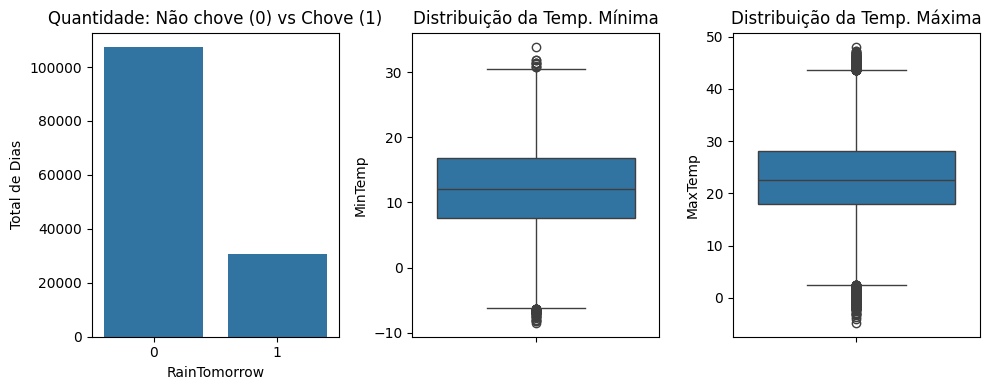

In [ ]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
sns.countplot(x='RainTomorrow', data=tabelaformatada)
plt.title('Quantidade: Não chove (0) vs Chove (1)')
plt.ylabel('Total de Dias')


plt.subplot(1, 3, 2)
sns.boxplot(y=tabelaformatada['MinTemp'])
plt.title('Distribuição da Temp. Mínima')

plt.subplot(1, 3, 3)
sns.boxplot(y=tabelaformatada['MaxTemp'])
plt.title('Distribuição da Temp. Máxima')

plt.tight_layout()
plt.show()

Distribuindo melhor: Acertos aumentam para chuva.

= Resultados: =
Acurácia: 65.77%
               precision    recall  f1-score   support

Não chove (0)       0.89      0.63      0.74     21465
     Chove(1)       0.37      0.74      0.49      6160

     accuracy                           0.66     27625
    macro avg       0.63      0.69      0.62     27625
 weighted avg       0.78      0.66      0.69     27625



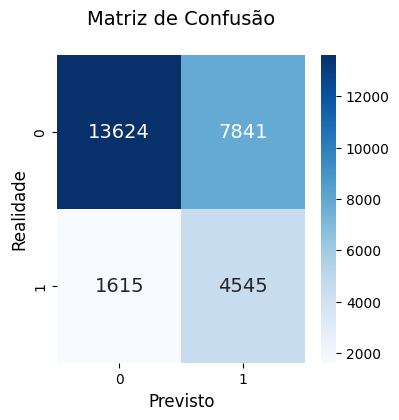

In [ ]:
x2 = tabelaformatada[['MinTemp', 'MaxTemp']]
y2 = tabelaformatada['RainTomorrow']

x_train, x_test, y_train, y_test = train_test_split(x2,y2, test_size = 0.2, random_state = 42, stratify = y2)


scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)


modelo = LogisticRegression(class_weight='balanced', random_state=42)
modelo.fit(x_train_scaled, y_train)


y_pred = modelo.predict(x_test_scaled)
matriz_confusao2 = confusion_matrix(y_test, y_pred)
acuracia2 = accuracy_score(y_test, y_pred)

print('= Resultados: =')
print(f'Acurácia: {acuracia2:.2%}')
print(classification_report(y_test, y_pred, target_names=['Não chove (0)', 'Chove(1)']))

plt.figure(figsize=(4, 4))
sns.heatmap(matriz_confusao2, annot=True, fmt='d', cmap='Blues', annot_kws={"size": 14})
plt.title('Matriz de Confusão\n', fontsize=14)
plt.ylabel('Realidade', fontsize=12)
plt.xlabel('Previsto', fontsize=12)
plt.show()

### Adicionando mais informações: Umidade

Sem balanceamento

= Resultado =
Acurácia: 82.87%

Relatório Detalhado:
              precision    recall  f1-score   support

     Sol (0)       0.84      0.96      0.90     21465
   Chuva (1)       0.72      0.38      0.50      6160

    accuracy                           0.83     27625
   macro avg       0.78      0.67      0.70     27625
weighted avg       0.82      0.83      0.81     27625



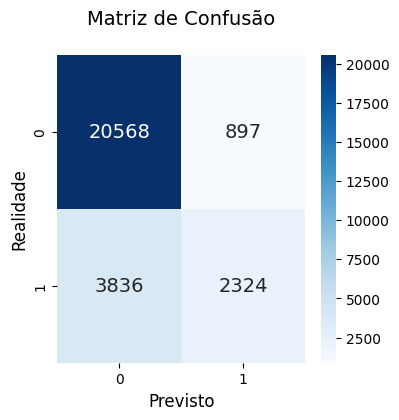

In [ ]:
x3 = tabelaformatada[['MinTemp', 'MaxTemp','Umidade3pm']]
y3 = tabelaformatada['RainTomorrow']

x_train, x_test, y_train, y_test = train_test_split(x3, y3, test_size=0.2, random_state=42, stratify=y3)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

modelo = LogisticRegression()
modelo.fit(x_train_scaled,y_train.values.ravel())


y_pred = modelo.predict(x_test_scaled)
acuracia3 = accuracy_score(y_test, y_pred)

print(f'= Resultado =')
print(f'Acurácia: {acuracia3:.2%}')
print('\nRelatório Detalhado:')
print(classification_report(y_test, y_pred, target_names=['Sol (0)', 'Chuva (1)']))

plt.figure(figsize=(4, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', annot_kws={"size": 14})
plt.title(f'Matriz de Confusão\n', fontsize=14)
plt.ylabel('Realidade', fontsize=12)
plt.xlabel('Previsto', fontsize=12)
plt.show()

Com balanceamento

= Resultado =
Acurácia: 72.31%

Relatório Detalhado:
              precision    recall  f1-score   support

     Sol (0)       0.91      0.72      0.80     21465
   Chuva (1)       0.43      0.74      0.54      6160

    accuracy                           0.72     27625
   macro avg       0.67      0.73      0.67     27625
weighted avg       0.80      0.72      0.74     27625





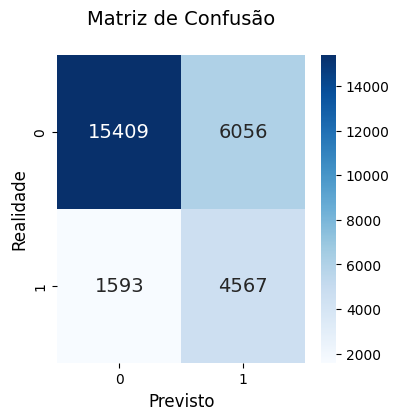

In [ ]:
x4 = tabelaformatada[['MinTemp', 'MaxTemp', 'Umidade3pm']]
y4 = tabelaformatada['RainTomorrow']

x_train, x_test, y_train, y_test = train_test_split(x4, y4, test_size=0.2, random_state=42, stratify=y4)


scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

modelo = LogisticRegression(class_weight='balanced', random_state=42)
modelo.fit(x_train_scaled, y_train)


y_pred = modelo.predict(x_test_scaled)

acuracia4 = accuracy_score(y_test, y_pred)

print(f'= Resultado =')
print(f'Acurácia: {acuracia4:.2%}')
print('\nRelatório Detalhado:')
print(classification_report(y_test, y_pred, target_names=['Sol (0)', 'Chuva (1)']))
print('\n')

plt.figure(figsize=(4, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', annot_kws={"size": 14})
plt.title(f'Matriz de Confusão\n', fontsize=14)
plt.xlabel('Previsto', fontsize = 12)
plt.ylabel('Realidade', fontsize=12)
plt.show()